# Exploring SCM Output

If the SCM ran successfully, it should generate an output directory containing these three files (and more): `progvar.nc`, `diagvar.nc`, and `diagvar2.nc`.

In [ ]:
scm_run_name = "ctrl"


In [3]:
# Setup
import datetime
import numpy as np
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib notebook
%matplotlib inline

# Specify your output directory here; for me it's the same folder as this notebook
RUNDIR = f'../../scm_runs/{scm_run_name}/'

# Useful constants
TCELS = 273.15  # 0 Celsius in K

# Variables for plotting
DEG = u'\u00B0'
DEGC = u'\u2103'
NHR = 71  # Number of simulation hours
FREQ = 4  # Frequency of output (# timesteps per hour)
DT = 1/FREQ
FREQ_IN = 1  # Frequency of input
DT_IN = 1/FREQ_IN
TMID = np.arange(NHR*FREQ + 1)*DT
TEDGE = (np.arange(NHR*FREQ + 2) - .5)*DT
TMID_IN = np.arange((NHR+1)*FREQ_IN)*DT_IN
TEDGE_IN = (np.arange((NHR+1)*FREQ_IN + 1) - .5)*DT_IN
TLIM = (-.5, NHR+.5)
TTICKS = np.arange(0, NHR, 12)
AXLINEARGS = dict(color='k', linewidth=.5)
LEGKWARGS = dict(loc='upper left', bbox_to_anchor=(1.01, 1))
ZMAX = 2e3
ZLABEL = 'Height, m'
ZLIM = (0, ZMAX)
ZTICKS = np.arange(0, ZMAX+1, 500)

In [4]:
# Load the input file to have as a reference
dsi = xr.load_dataset(f"../../scm_runs/{scm_run_name}/scm_in.nc", decode_times=False)

#Define a few variables for easier plotting later
IZ0 = np.nonzero(dsi.height_f.isel(time=0).data > ZMAX)[0][-1] - 1
STARTDATE = datetime.datetime.strptime(
    dsi.time.attrs['units'], 'seconds since %Y-%m-%dT%H:%M:%SZ')
TLABEL = STARTDATE.strftime('Time, hours since %Y-%m-%d 00Z')
ZEBAR_IN = dsi.height_h.mean('time').isel(nlevp1=slice(IZ0, None))
ZMBAR_IN = dsi.height_f.mean('time').isel(nlev=slice(IZ0, None))

## `progvar.nc` 

The file `progvar.nc` contains the model prognostic variables - those for which an evolution equation
$$ \frac{\partial}{\partial t} \cdot = \ldots $$
is solved. It also contains a few extra related variables.

In [5]:
# Load the prognostic variables output file
dsp = xr.load_dataset(RUNDIR + 'progvar.nc', decode_times=False)

# Pull out some variables for plotting
ZEBAR = dsp.height_h.mean('time').isel(nlevp1=slice(IZ0, None))
ZMBAR = dsp.height_f.mean('time').isel(nlev=slice(IZ0, None))

# Show the prognostic file
dsp

<xarray.Dataset> Size: 3MB
Dimensions:            (nlev: 137, nlevp1: 138, nlevs: 4, time: 285)
Coordinates:
  * nlev               (nlev) int32 548B 1 2 3 4 5 6 ... 132 133 134 135 136 137
  * nlevp1             (nlevp1) int32 552B 1 2 3 4 5 6 ... 134 135 136 137 138
  * nlevs              (nlevs) int32 16B 1 2 3 4
  * time               (time) float32 1kB 0.0 900.0 ... 2.547e+05 2.556e+05
Data variables: (12/36)
    pressure_f         (time, nlev) float32 156kB 1.0 2.551 ... 1.002e+05
    pressure_h         (time, nlevp1) float32 157kB 0.0 2.0 ... 1.003e+05
    height_f           (time, nlev) float32 156kB 7.633e+04 7.112e+04 ... 29.88
    height_h           (time, nlevp1) float32 157kB 8.904e+04 7.25e+04 ... 20.11
    relative_humidity  (time, nlev) float32 156kB 8.495e-05 4.3e-05 ... 0.8864
    t                  (time, nlev) float32 156kB 188.7 200.3 ... 281.3 281.5
    ...                 ...
    ltlt               (time) float32 1kB 284.1 284.1 284.1 ... 283.9 283.9
    lshf               (time) float32 1kB 0.6507 0.6508 0.6509 ... 0.65 0.65
    lict               (time) float32 1kB 273.1 273.1 273.1 ... 273.1 273.1
    licd               (time) float32 1kB 2.289e-05 0.0 0.0 0.0 ... 0.0 0.0 0.0
    cl                 (time) float32 1kB 0.4771 0.4771 0.4771 ... 0.4771 0.4771
    q_sat              (time, nlev) float32 156kB 0.0 0.0 ... 0.006823 0.006881
Attributes:
    title:         SCM: 36r1  Sim: trref_wind
    modelID:       36r1
    simulationID:  trref_wind
    dataID:        SCM_OUTPUT
    start_day:     20201008
    start_hour:    0

Many of the variables from the input file are here.

- The pressure and height arrays on the standard model levels `pressure_f`, `height_f` and at the cell edges or 'half'-levels `pressure_h`, `height_h`.
- The standard variables: temperature `t`, specific humidity `q`, and horizontal winds `u`, `v`.
- The condensed water (cloud liquid `ql`, cloud ice `qi`, rain `qr`, and snow `qsn`) and cloud fraction `cloud_fraction`.
- The temperature and moisture content of the surface skin `t_skin`, `q_skin` and the soil `t_soil`, `q_soil`.
- The snow depth, temperature, albedo, and density (`snow`, `t_snow`, `albedo_snow`, `density_snow`).
- The various lake fields (`lmlt`, `lmld`, `lblt`, `ltlt`, `lshf`, `lict`, `licd`) along with the constant lake depth and coverage `dl`, `cl`.
- Auxiliary thermodynamic variables: potential and equivalent potential temperature `pot_temperature`, `pot_temp_e`; saturation specific humidity and relative humidity `q_sat`, `relative_humidity`; and the dry and moist static energies `dry_st_energy`, `moist_st_energy`.

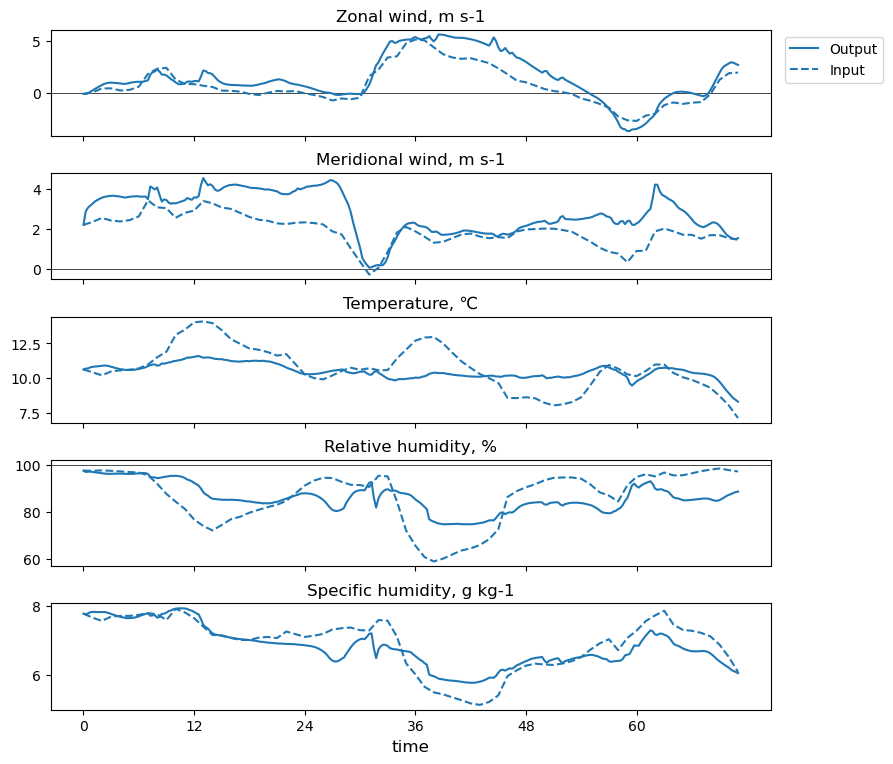

In [6]:
# Plot near-surface variables and compare to input

# Define which variables to plot
vbls = [
    ['Zonal wind, m s-1', dsp.u.isel(nlev=-1), dsi.u.isel(nlev=-1)],
    ['Meridional wind, m s-1', dsp.v.isel(nlev=-1), dsi.v.isel(nlev=-1)],
    [f'Temperature, {DEGC}', dsp.t.isel(nlev=-1)-TCELS, dsi.t.isel(nlev=-1)-TCELS],
    ['Relative humidity, %', dsp.relative_humidity.isel(nlev=-1)*1e2, dsi.relative_humidity.isel(nlev=-1)*1e2],
    ['Specific humidity, g kg-1', dsp.q.isel(nlev=-1)*1e3, dsi.q.isel(nlev=-1)*1e3]
]
nrows = len(vbls)

lineargs = dict(color='C0')

# Set up the figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(9, 8))
fig.subplots_adjust(left=.05, right=.85, bottom=.1, top=.95, hspace=.35)
axs[-1].set_xlabel('time', fontsize=12)
axs[-1].set_xticks(TTICKS)
lines = [list() for irow in range(nrows)]
axs[0].axhline(0, **AXLINEARGS)
axs[1].axhline(0, **AXLINEARGS)
axs[3].axhline(100, **AXLINEARGS)

# Plot each pair of variables
for (irow, (title, vblout, vblin)) in enumerate(vbls):
    ax = axs[irow]
    ax.set_title(title, fontsize=12)
    lines[irow] += ax.plot(dsp.time.data/3600, vblout, **lineargs)
    lines[irow] += ax.plot(dsi.time.data/3600, vblin, linestyle='--', **lineargs)


# Add a legend
leg = axs[0].legend(lines[0], ['Output', 'Input'], **LEGKWARGS)
plt.show()

Compared to the original ERA5 data, the simulated winds are fairly accurate. The meridional wind is a bit too strong initially, but the transition from southerly to westerly winds at the frontal passage is captured. The temperature does not show nearly as much of a diurnal cycle in the simulation but more of a smooth downward trend. As a result, the variations in relative humidity (even after the frontal passage) are not as large. The specific humidity -- the actual water content of the air -- is fairly similar between the simulation and ERA5, though the simulation doesn't dry out as much with the frontal passage.

Other variables and plots for this file are similar to those in the CaseStudy notebook, so I will not repeat them here.

## `diagvar.nc`

The majority of the new variables to explore are in `diagvar.nc`. This file includes most of the non-prognostic variables; variables calculated by the model during the process of solving the prognostic equations.

In [7]:
# Load data from diagvar.nc
dsd = xr.load_dataset(RUNDIR + 'diagvar.nc', decode_times=False)
dsd

<xarray.Dataset> Size: 8MB
Dimensions:              (nlev: 137, nlevp1: 138, nlevs: 4, ntiles: 9, norg: 4,
                          time: 285, ncextr: 137)
Coordinates:
  * nlev                 (nlev) int32 548B 1 2 3 4 5 6 ... 133 134 135 136 137
  * nlevp1               (nlevp1) int32 552B 1 2 3 4 5 6 ... 134 135 136 137 138
  * nlevs                (nlevs) int32 16B 1 2 3 4
  * ntiles               (ntiles) int32 36B -2147483647 ... -2147483647
  * norg                 (norg) int32 16B -2147483647 ... -2147483647
  * time                 (time) float32 1kB 0.0 900.0 ... 2.547e+05 2.556e+05
  * ncextr               (ncextr) int32 548B -2147483647 ... -2147483647
Data variables: (12/107)
    pressure_f           (time, nlev) float32 156kB 1.0 2.551 ... 1.002e+05
    pressure_h           (time, nlevp1) float32 157kB 0.0 2.0 ... 1.003e+05
    height_f             (time, nlev) float32 156kB 7.633e+04 ... 29.88
    height_h             (time, nlevp1) float32 157kB 8.904e+04 ... 20.11
    wat_vap_path         (time) float32 1kB 18.84 18.69 18.6 ... 12.73 12.57
    liq_wat_path         (time) float32 1kB 0.005664 0.004592 ... 0.01722
    ...                   ...
    turb_flx_ice         (time, nlevp1) float32 157kB 0.0 0.0 0.0 ... 0.0 0.0
    turb_flx_liq         (time, nlevp1) float32 157kB 0.0 9.139e-08 ... 0.0 0.0
    gwd_flx_u            (time, nlevp1) float32 157kB 0.0 -5.881e-05 ... 0.0 0.0
    gwd_flx_v            (time, nlevp1) float32 157kB 0.0 1.949e-05 ... 0.0 0.0
    sw_rad_flux          (time, nlevp1) float32 157kB 0.0 0.0 ... 0.0 2.22e-14
    lw_rad_flux          (time, nlevp1) float32 157kB -224.5 -224.5 ... -49.73
Attributes:
    title:         SCM: 36r1  Sim: trref_wind
    modelID:       36r1
    simulationID:  trref_wind
    dataID:        SCM_OUTPUT
    start_day:     20201008
    start_hour:    0

This is a **lot** of variables to try to understand. I will try to break these down into a few key groups.

### Standard diagnostics

Let's start with a few of the more standard output variables. `pbl_height` is the boundary layer height, calculated based on the bulk Richardson number between each model layer and the lowest model layer. Further down, we have the horizontal winds and wind gust at 10 m `u_wind_10m, v_wind_10m, wind_gust`. These are calculated from the values at other model levels using the similarity functions, after the turbulent fluxes have been calculated. Similarly, we have the air and dew point temperatures at 2 m `temperature_2m, dew_point_2m`.

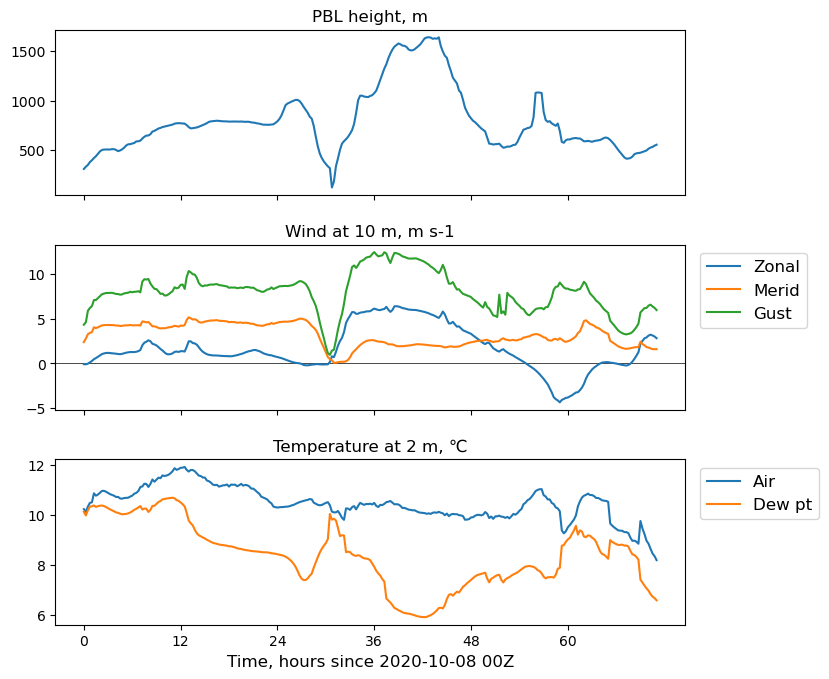

In [8]:
# Plot several of the standard variables

# Define which fields to plot
toplot = [
    dict(title='PBL height, m', names=['pbl_height']),
    dict(title='Wind at 10 m, m s-1',
         names=['u_wind_10m', 'v_wind_10m', 'wind_gust'],
         labels=['Zonal', 'Merid', 'Gust']),
    dict(title=f'Temperature at 2 m, {DEGC}', offset=TCELS,
         names=['temperature_2m', 'dew_point_2m'],
         labels=['Air', 'Dew pt'])
]
nrows = len(toplot)

# Set up the figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(9, 7))
fig.subplots_adjust(left=.1, bottom=.1, right=.8, top=.95, hspace=.3)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xticks(TTICKS)
axs[1].axhline(0, **AXLINEARGS)  # Axis line

# Plot each set of values
lines = [list() for irow in range(nrows)]
legs = [None for irow in range(nrows)]
for (irow, (ax, ls, pdict)) in enumerate(zip(axs, lines, toplot)):
    ax.set_title(pdict['title'], fontsize=12)
    offset = pdict.get('offset', 0)
    for name in pdict['names']:
        val = dsd[name].data - offset
        ls += ax.plot(TMID, val)
    if 'labels' in pdict:
        legs[irow] = ax.legend(ls, pdict['labels'], fontsize=12, **LEGKWARGS)
plt.show()

The 10-m winds and 2-m temperatures are always a bit strange over the first model timesteps while the turbulence equilibriates. We see the temperature rising and falling throughout the first day along with the BLH. Around hour 30 a front passes through, enabling some convection and a large increase in BLH. The effect of this expansion is a decrease in near-surface humidity - strong mixing of dry free-tropospheric air down to the surface. We also see the surface winds shift from southerly to westerly.

### Surface fluxes

The next set of variables to look at would be the surface fluxes. These include:

- Net radiative fluxes in the SW and LW `sfc_swrad, sfc_lwrad`. There are also the downward-only fluxes `*_down` and the clear-sky fluxes `*_clr`. Related are the top-of-atmosphere fluxes `top_swrad, top_lwrad` and the surface albedo and emissivity `sfc_albedo, sfc_emiss`.
- The surface sensible and latent heat fluxes `sfc_sen_flx, sfc_lat_flx`. We'll look at the "tiled" versions `*_ti` that show the fluxes over each surface type later.
- The zonal and meridional surface stress `u_sfc_strss, v_sfc_strss` which also have tiled versions.

The convention for all of these fluxes is that they are **positive downwards**. Evaporation from the surface leads to a _negative_ latent heat flux, for example.

Let's start by building up an energy budget. I'll do this in three stages: the radiative fluxes, the turbulent fluxes, and then the net flux.

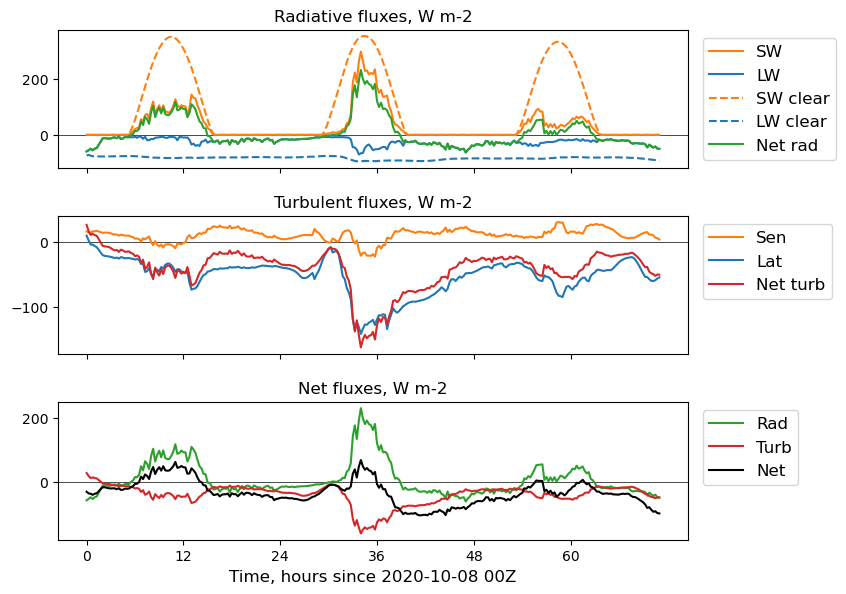

In [9]:
# Plot the surface energy balance terms

# Define which variables to plot
netrad = dsd.sfc_swrad + dsd.sfc_lwrad
netturb = dsd.sfc_sen_flx + dsd.sfc_lat_flx
toplot = [
    dict(
        title='Radiative fluxes, W m-2',
        vals=[dsd.sfc_swrad, dsd.sfc_lwrad, dsd.sfc_swrad_clr, dsd.sfc_lwrad_clr, netrad],
        labels=['SW', 'LW', 'SW clear', 'LW clear', 'Net rad'],
        kwargs=[
            dict(color='C1'), dict(color='C0'), dict(color='C1', ls='--'),
            dict(color='C0', ls='--'), dict(color='C2')]),
    dict(
        title='Turbulent fluxes, W m-2',
        vals=[dsd.sfc_sen_flx, dsd.sfc_lat_flx, netturb],
        labels=['Sen', 'Lat', 'Net turb'],
        kwargs=[dict(color='C1'), dict(color='C0'), dict(color='C3')]),
    dict(
        title='Net fluxes, W m-2',
        vals=[netrad, netturb, netrad + netturb],
        labels=['Rad', 'Turb', 'Net'],
        kwargs=[dict(color='C2'), dict(color='C3'), dict(color='k')])
]
nrows = len(toplot)

# Set up figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.8, top=.95, hspace=.35)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xticks(TTICKS)

# Plot each set of quantities
lines = [list() for irow in range(nrows)]
legs = [None for irow in range(nrows)]
for (irow, (ax, ls, pdict)) in enumerate(zip(axs, lines, toplot)):
    ax.set_title(pdict['title'], fontsize=12)
    ax.axhline(0, **AXLINEARGS)  # Axis line
    for (val, kwargs) in zip(pdict['vals'], pdict['kwargs']):
        ls += ax.plot(TMID, val.data, **kwargs)
    legs[irow] = ax.legend(ls, pdict['labels'], fontsize=12, **LEGKWARGS)
plt.show()

Here, positive fluxes correspond to energy entering the surface.
We see a clear peak in the SW fluxes during the daytime. The clear-sky LW flux would be fairly constantly negative. However, the actual LW flux is close to zero due to the presence of clouds that also greatly diminish the magnitude of the SW fluxes (especially on the third day).

The sensible heat flux is generally positive, indicating that the atmosphere is heating the surface. The latent heat fluxes are much larger in magnitude and almost always negative. (This column's surface consists of 52% land and 48% coastal water; both of these fluxes are consistent with a land-sea breeze.)

The primary energy balance of the surface is then SW heating balanced by latent heat flux. This takes place during the daytime; at night all fluxes are close to zero. Up until 36 hours, the radiative flux is stronger and there is a net energy flux into the surface. After the frontal passage, weak LW cooling combined with moderate latent heat flux leads to a steady energy loss from the surface.

For discussing the surface stresses, we can combine them with the surface roughness lengths `rough_len_mom, rough_len_heat` and the total turbulent dissipation `turb_diss` to get a sense of the intensity of the turbulence.

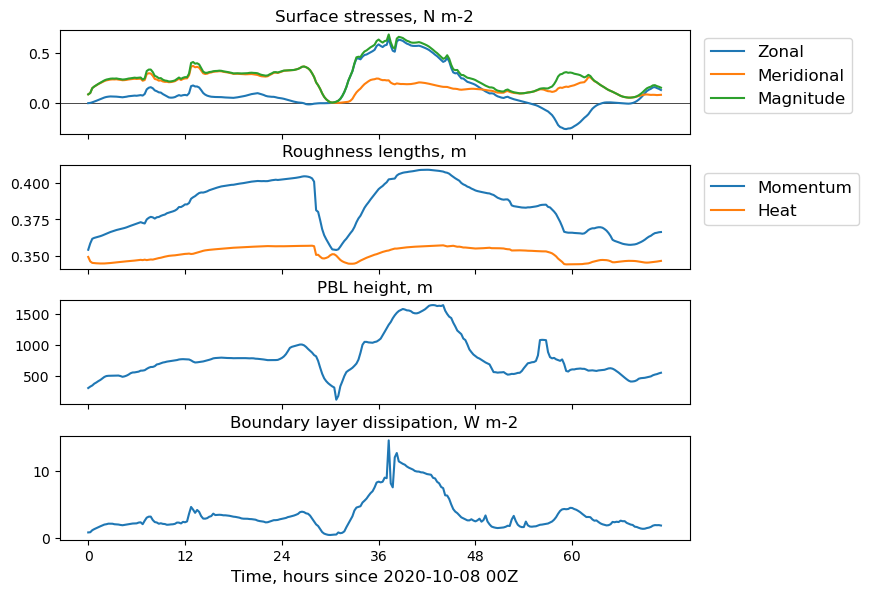

In [10]:
# Plot the kinematic turbulence terms

# Define the variables to plot
strssmag = np.sqrt(dsd.u_sfc_strss**2 + dsd.v_sfc_strss**2)
toplot = [
    dict(title='Surface stresses, N m-2', vals=[dsd.u_sfc_strss, dsd.v_sfc_strss, strssmag],
         labels=['Zonal', 'Meridional', 'Magnitude']),
    dict(title='Roughness lengths, m', vals=[dsd.rough_len_mom, dsd.rough_len_heat],
         labels=['Momentum', 'Heat']),
    dict(title='PBL height, m', vals=[dsd.pbl_height], names=['pbl_height']),
    dict(title='Boundary layer dissipation, W m-2', vals=[dsd.turb_diss])
]
nrows = len(toplot)

# Set up figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.8, top=.95, hspace=.3)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xticks(TTICKS)

# Plot each quantity
axs[0].axhline(0, **AXLINEARGS)  # Axis line
lines = [list() for irow in range(nrows)]
legs = [None for irow in range(nrows)]
for (irow, (ax, ls, pdict)) in enumerate(zip(axs, lines, toplot)):
    ax.set_title(pdict['title'], fontsize=12)
    for val in pdict['vals']:
        ls += ax.plot(TMID, val.data)
    if 'labels' in pdict:
        legs[irow] = ax.legend(ls, pdict['labels'], fontsize=12, **LEGKWARGS)
plt.show()

These plots show a slow build-up of turbulent energy over the first day, followed by strong turbulence after the frontal passage. The total surface stress tracks the boundary layer dissipation, with the direction of the stress (roughly) following the mean wind. For this surface the roughness length for momentum varies much more than that of heat but they are the same order of magnitude. This is because the surface is primarily water and high vegetation; for most low vegetation types, the roughness length for heat is 1-2 orders of magnitude smaller.

### Clouds and precipitation

There are several variables related to clouds and precipitation.

- The integrated water paths for vapor, liquid, and ice `wat_vap_path, liq_wat_path, ice_wat_path`.
- The coverage of low-, mid-, and high-level clouds `low_cloud, middle_cloud, high_cloud` as well as total cloud coverage `total_cloud`;
- The rain and snowfall rates, divided into "convective" (handled by the turbulence scheme) and "stratiform" (handled by the rest of the model) categories: `conv_rain, conv_snow, stra_rain, stra_snow`.

While these quantities aren't always directly related to the boundary layer, they can help describe some of the other features. For example, high liquid water path typically suggests large downward LW radiation; convective rain suggests sufficient turbulence to trigger convection.

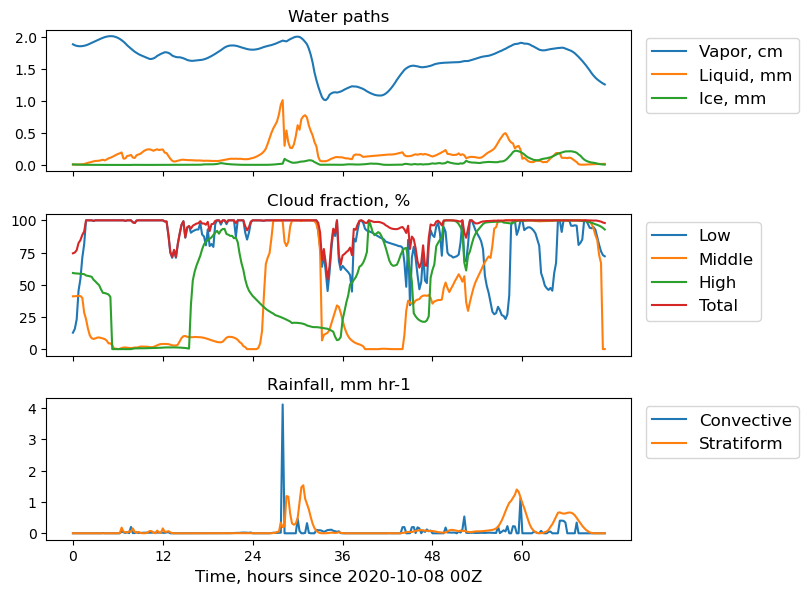

In [11]:
# Plot clouds and precip

# Define variables to plot
toplot = [
    dict(
        title='Water paths',
        vals=[dsd.wat_vap_path*.1, dsd.liq_wat_path, dsd.ice_wat_path],
        labels=['Vapor, cm', 'Liquid, mm', 'Ice, mm']),
    dict(
        title='Cloud fraction, %', scale=1e2,
        names=['low_cloud', 'middle_cloud', 'high_cloud', 'total_cloud'],
        labels=['Low', 'Middle', 'High', 'Total']),
    dict(
        title='Rainfall, mm hr-1', scale=3600,
        names=['conv_rain', 'stra_rain'],
        labels=['Convective', 'Stratiform'])
]
nrows = len(toplot)

# Set up figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.75, top=.95, hspace=.3)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xticks(TTICKS)

# Plot each quantity
lines = [list() for irow in range(nrows)]
legs = [None for irow in range(nrows)]
for (irow, (ax, ls, pdict)) in enumerate(zip(axs, lines, toplot)):
    ax.set_title(pdict['title'], fontsize=12)
    scale = pdict.get('scale', 1)
    if 'vals' in pdict:
        vals = pdict['vals']
    else:
        vals = [dsd[name]*scale for name in pdict['names']]
    for val in vals:
        ls += ax.plot(TMID, val.data)
    legs[irow] = ax.legend(ls, pdict['labels'], fontsize=12, **LEGKWARGS)
plt.show()

The front passing coincides with a build-up of liquid water, followed by some intense convective rain and a dryer atmosphere (as seen in the water vapor path). The total cloud cover is dominated by low clouds initially, but the convection coincides with thick mid-level clouds.

### Tiled variables

If you want to dig into the fields over each tile, you need to see the IFS documentation, part 4, table 2.6 to get the 9 different tile types; figure 8.1 is a schematic of the result. They are:

1. Open ocean
2. Sea ice
3. Interception layer (water on vegetation)
4. Low vegetation
5. Exposed snow
6. High vegetation
7. Shaded snow
8. Bare ground
9. Lake/coastal water

The surface scheme actually calculates turbulent fluxes and a skin temperature for each tile separately but using the same overlying atmosphere. These individual values are then aggregated to get the net fluxes we saw above.

NB: The SCM incorrectly gives the tiled fluxes the `nlev` dimension instead of `ntiles`! Only the first 9 values are relevant.

In [12]:
# Define the names of the tiles
tilenames = [
    'Open ocean', 'Sea ice', 'Interception layer', 'Low vegetation',
    'Exposed snow', 'High vegetation', 'Shaded snow', 'Bare ground',
    'Lake/coastal']
# Define the tiles relevant to this simulation and get their indices
tilesused = [
    'Open ocean', 'Interception layer', 'Low vegetation', 'High vegetation',
    'Bare ground', 'Lake/coastal']
tileinds = np.array([tilenames.index(tile) for tile in tilesused])

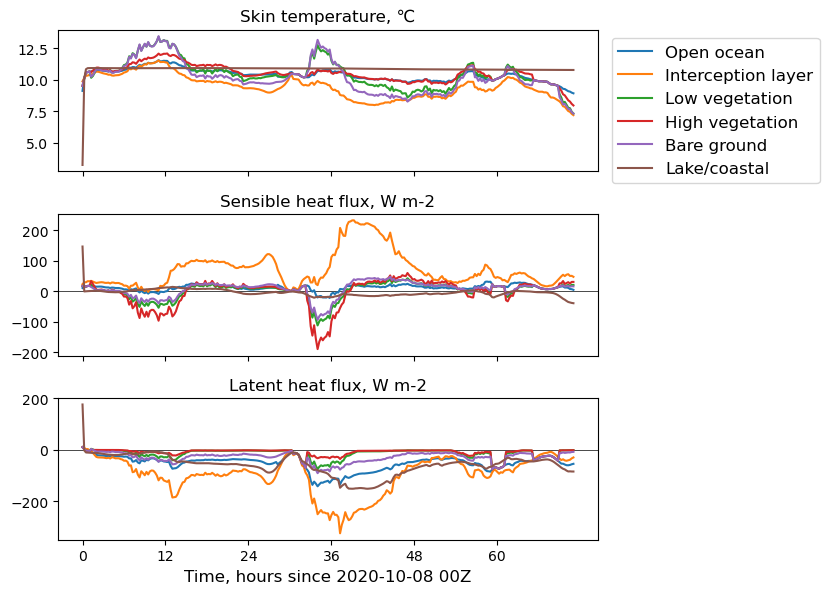

In [13]:
# Compare the skin temperature and energy fluxes of each tile

# Define quantities to plot
toplot = [
    dict(title=f'Skin temperature, {DEGC}', name='t_skin_ti', offset=TCELS),
    dict(title='Sensible heat flux, W m-2', name='sfc_sen_flx_ti'),
    dict(title='Latent heat flux, W m-2', name='sfc_lat_flx_ti')
]
nrows = len(toplot)

# Set up figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.7, top=.95, hspace=.3)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xticks(TTICKS)
for ax in axs[1:]:
    ax.axhline(0, **AXLINEARGS)

# Plot each quantity
lines = [list() for irow in range(nrows)]
for (ax, ls, pdict) in zip(axs, lines, toplot):
    ax.set_title(pdict['title'], fontsize=12)
    offset = pdict.get('offset', 0)
    ls += ax.plot(TMID, dsd[pdict['name']].isel(nlev=tileinds).data-offset)

# Add a legend
leg = axs[0].legend(lines[0], tilesused, fontsize=12, **LEGKWARGS)
plt.show()

The bare ground and low vegetation (purple and green lines) behave similarly, showing a large response to daytime heating and a sensible heat flux _upwards_ from the surface (i.e. surface heats up the air above). The sensible heat flux from the high vegetation is also upward and quite large. The open water (coastal water) has small sensible heat flux but a large negative latent heat flux (evaporation).

However, the largest fluxes come from the interception layer: a conceptual water-storage reservoir associated with vegetation and the land surface. A large negative latent heat flux (evaporation of dew and soil water) and a positive sensible heat flux (absorbing heat from the atmosphere) are associated with it in this case. Note that the interception layer also has the lowest skin temperature. The latent heat lost from evaporation cools this layer tremendously, causing it to be cooler than the atmosphere. Thus this layer absorbs heat from the atmosphere while the other tiles mostly supply heat to the atmosphere.

Do keep in mind that the above values are the fluxes _over that tile in particular_. To get the net fluxes, each value must be multiplied by the fraction of the surface covered by that tile. Unfortunately, this quantity is not output by the model and the documentation is unclear as to how the area of the interception layer in particular is calculated. (Also note that the documentation for cycle 43r3 has not been updated to reflect the fact that mixed land-water tiles have been included since 41r1!) The tiled fluxes can be helpful in understanding certain features but are difficult to use quantitatively.

### Tendencies and fluxes

The last major categories of variables are the tendencies (rate of change of a prognostic variable) and fluxes (transport of quantity over horizontal layers). The tendencies `tend_*` are the time derivatives of the primary variables: horizontal wind, temperature, and water amounts. They are further divided into the tendency due to dynamics `tend_*_d`, i.e. the portion coming from advection; and the tendency due to physics `tend_*_p`, which often means the sub-grid scale parameterizations.

The fluxes are defined at the grid cell edges (dimension `nlevp1`). They include:

- The fluxes of rain and snow throughout the column, for both stratiform and convective precipitation `stra_rain_3d, stra_snow_3d, conv_rain_3d, conv_snow_3d`.
- The fluxes of water vapor, heat, and momentum from sub-grid scale convection `conv_flx_*`.
- The (sub-grid scale) turbulent fluxes `turb_flx_*` of water vapor, heat, momentum, and condensed water.
- The momentum flux from gravity wave drag `gwd_u, gwd_v`.
- The net radiative fluxes throughout the column `*_rad_flux`.

Of these, the turbulent fluxes are most relevant to our interests as they can provide a picture of the vertical structure of the turbulence.

NB: In these variables, heat is denoted by the later `s` and the quantity being fluxed is the dry static energy.

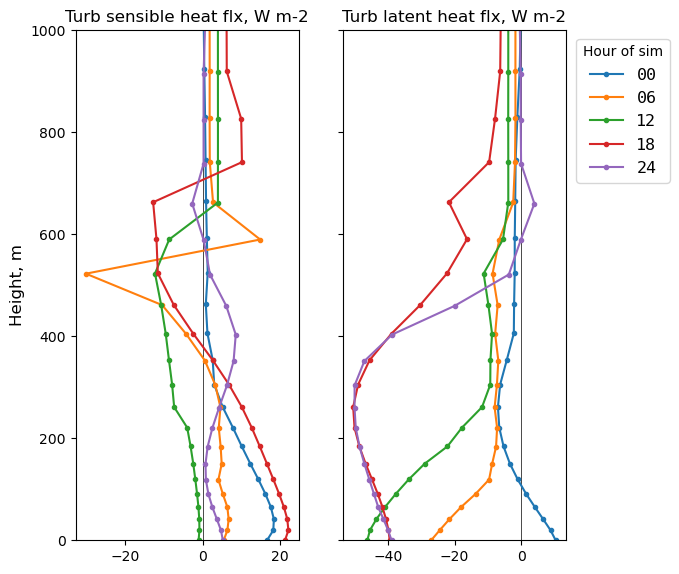

In [14]:
# Plot turbulent heat flux profiles at specific times

# Extract time and height arrays
ttarget = np.arange(0, 25, 6)  # 6-hourly profiles for the first day
tinds = ttarget*FREQ

zmax = 1e3  # Plot up to 1 km
# Need the heights with dimension nlevp1
z = dsd.height_h.isel(time=tinds).data
z -= z[0, -1]
iz0 = np.nonzero(np.all(z > zmax, axis=0))[0][-1]
z = z[:, iz0:]

# Define variables to plot
# Multiply the water vapor flux by latent heat of evaporation to get an energy flux
toplot = [
    dict(title='Turb sensible heat flx, W m-2', name='turb_flx_s'),
    dict(title='Turb latent heat flx, W m-2', scale=2.5008e6, name='turb_flx_wv')
]
ncols = len(toplot)

# Set up figure
fig, axs = plt.subplots(ncols=ncols, sharey=True, figsize=(7, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.8, top=.95)
axs[0].set_ylabel('Height, m', fontsize=12)
axs[0].set_ylim(0, zmax)

# Plot each quantity at the selected times
lines = [list() for icol in range(ncols)]
for (ax, ls, pdict) in zip(axs, lines, toplot):
    ax.set_title(pdict['title'], fontsize=12)
    ax.axvline(0, color='k', linewidth=.5)
    scale = pdict.get('scale', 1)
    val = dsd[pdict['name']].isel(time=tinds, nlevp1=slice(iz0, None)).data*scale
    ls += ax.plot(val.T, z.T, marker='.')

# Add a legend
labels = [f'{tval:02d}' for tval in ttarget]
leg = axs[-1].legend(
    lines[-1], labels, title='Hour of sim',
    prop=dict(family='monospace', size=12), **LEGKWARGS)
plt.show()

Recall that the fluxes are defined as positive downwards; only the sensible heat flux at 12Z is upwards at the surface. This is clearer in the latent heat fluxes. Most of these are negative at the surface, implying evaporation. The profile at 00Z has positive water vapor flux, i.e. condensation (the formation of dew - notice how early in the night it forms).

## `diagvar2.nc`

The last output file is `diagvar2.nc`. This file was initially designed for user-defined custom output variables. I don't think it will be very useful for this lab but include it for completeness.

In [15]:
# Load the extra diagnostic variables

dsx = xr.load_dataset(RUNDIR + 'diagvar2.nc', decode_times=False)
dsx

<xarray.Dataset> Size: 6MB
Dimensions:           (nlev: 137, nlevp1: 138, nlevs: 4, ntiles: 9, norg: 4,
                       time: 285, ncextr: 137)
Coordinates:
  * nlev              (nlev) int32 548B 1 2 3 4 5 6 ... 132 133 134 135 136 137
  * nlevp1            (nlevp1) int32 552B 1 2 3 4 5 6 ... 134 135 136 137 138
  * nlevs             (nlevs) int32 16B 1 2 3 4
  * ntiles            (ntiles) int32 36B -2147483647 -2147483647 ... -2147483647
  * norg              (norg) int32 16B -2147483647 -2147483647 ... -2147483647
  * time              (time) float32 1kB 0.0 900.0 ... 2.547e+05 2.556e+05
  * ncextr            (ncextr) int32 548B -2147483647 ... -2147483647
Data variables: (12/77)
    acc_conv_rain     (time) float32 1kB 0.0 0.0 0.0 ... 1.397e-05 1.392e-05
    acc_conv_snow     (time) float32 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    acc_stra_rain     (time) float32 1kB 2.009e-07 1.586e-07 ... 4.158e-05
    acc_stra_snow     (time) float32 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    acc_top_swrad     (time) float32 1kB 0.0 0.0 0.0 0.0 ... 72.55 72.3 72.04
    acc_sfc_swrad     (time) float32 1kB 2.22e-14 2.22e-14 ... 32.35 32.24
    ...                ...
    extra_col_20      (time, ncextr) float32 156kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    extra_col_21      (time, ncextr) float32 156kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    extra_col_22      (time, ncextr) float32 156kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    extra_col_23      (time, ncextr) float32 156kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    extra_col_24      (time, ncextr) float32 156kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    extra_col_25      (time, ncextr) float32 156kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
Attributes:
    title:         SCM: 36r1  Sim: trref_wind
    modelID:       36r1
    simulationID:  trref_wind
    dataID:        SCM_OUTPUT
    start_day:     20201008
    start_hour:    0

Most of the variables in this file are accumulated versions of the fluxes from `diagvar.nc`. In a global forecast model, the output might be written every 3 or 6 hours; the instantaneous fluxes are too variable to be useful. Instead, the accumulated values such as "total rainfall since last time step" are more reliable. For the purpose of understanding the boundary layer, the instantaneous fluxes are better but I wanted to mention this point for those of you interested in forecasting.

The last set of variables are extra fluxes related to cloud processes. They're all fairly arcane fields: the heat flux associated with rainfall, or the flux of liquid water used to ensure that liquid water concentrations are never negative.

## MYCODE

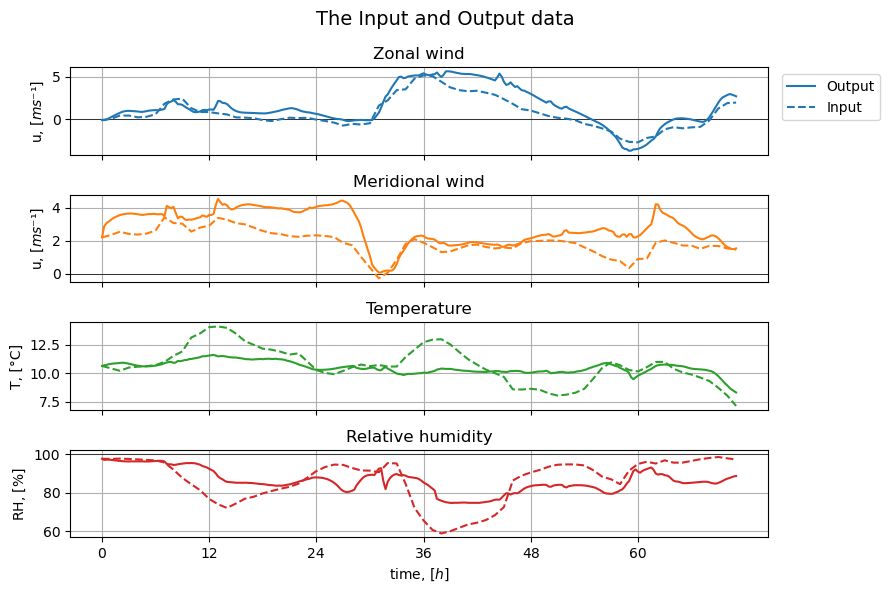

AttributeError: module 'matplotlib.pyplot' has no attribute 'save'

In [ ]:
# Plot near-surface variables and compare to input
scm_run_name = "ctrl"
RUNDIR = f'../../scm_runs/{scm_run_name}/'

dsp = xr.load_dataset(RUNDIR + 'progvar.nc', decode_times=False)

# Define which variables to plot
vbls = [
    ['Zonal wind', dsp.u.isel(nlev=-1), dsi.u.isel(nlev=-1)],
    ['Meridional wind', dsp.v.isel(nlev=-1), dsi.v.isel(nlev=-1)],
    [f'Temperature', dsp.t.isel(nlev=-1)-TCELS, dsi.t.isel(nlev=-1)-TCELS],
    ['Relative humidity', dsp.relative_humidity.isel(nlev=-1)*1e2, dsi.relative_humidity.isel(nlev=-1)*1e2]
    ]
nrows = len(vbls)

# Set up the figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, figsize=(9, 6))
axs[-1].set_xlabel('time, $[h]$')
axs[-1].set_xticks(TTICKS)
lines = [list() for irow in range(nrows)]
axs[0].axhline(0, **AXLINEARGS)
axs[1].axhline(0, **AXLINEARGS)
axs[3].axhline(100, **AXLINEARGS)
axs[0].grid(True)
axs[1].grid(True)
axs[2].grid(True)
axs[3].grid(True)
axs[0].set_ylabel(r"u, $\left[ms⁻¹\right]$")
axs[1].set_ylabel(r"u, $\left[ms⁻¹\right]$")
axs[2].set_ylabel(r"T, [°C]")
axs[3].set_ylabel(r"RH, $[\%]$")


# Plot each pair of variables
for (irow, (title, vblout, vblin)) in enumerate(vbls):
    ax = axs[irow]
    ax.set_title(title, fontsize=12)
    lines[irow] += ax.plot(dsp.time.data/3600, vblout, color=f"C{irow}")
    lines[irow] += ax.plot(dsi.time.data/3600, vblin, linestyle='--', color=f"C{irow}")


# Add a legend
leg = axs[0].legend(lines[0], ['Output', 'Input'], **LEGKWARGS)
plt.suptitle("The Input and Output data", fontsize=14)
plt.tight_layout()
plt.show()
